# Λευτερης Παυλίδης - 5332
# Σωτηρης Ζωτος - 5227

## IMPORTS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

np.random.seed(42)
tf.random.set_seed(42)


## ΦΟΡΤΩΣΗ ΚΑΙ ΠΡΟΕΠΕΞΕΡΓΑΣΙΑ ΔΕΔΟΜΕΝΩΝ

In [3]:
train_path = 'sign_mnist_train.csv'
test_path = 'sign_mnist_test.csv'

print("Φόρτωση δεδομένων...")
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)


y_train_raw = train_df['label'].values
X_train_raw = train_df.drop('label', axis=1).values

y_test = test_df['label'].values
X_test_raw = test_df.drop('label', axis=1).values


X_train_raw = X_train_raw / 255.0
X_test_raw = X_test_raw / 255.0

X_train_spatial = X_train_raw.reshape(-1, 28, 28, 1)
X_test_spatial = X_test_raw.reshape(-1, 28, 28, 1)


X_train, X_val, y_train, y_val = train_test_split(
    X_train_spatial, y_train_raw, 
    test_size=0.2, 
    stratify=y_train_raw, 
    random_state=42
)

labels_present = sorted(np.unique(y_train_raw))
num_classes = len(labels_present)
label_to_index = {label: idx for idx, label in enumerate(labels_present)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

def remap_labels(labels):
    return np.array([label_to_index[int(label)] for label in labels], dtype=np.int32)

def label_to_asl_letter(label):
    return chr(ord('A') + int(label))

print(f"Train set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test_spatial.shape}")

Φόρτωση δεδομένων...
Train set shape: (21964, 28, 28, 1)
Validation set shape: (5491, 28, 28, 1)
Test set shape: (7172, 28, 28, 1)


## CNN Autoencoder για εξαγωγή χαρακτηριστικών

In [4]:
def build_cnn_autoencoder(latent_dim):
    encoder_inputs = layers.Input(shape=(28, 28, 1), name='Encoder_Input')
    

    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(encoder_inputs)
    x = layers.MaxPooling2D((2, 2), padding='same')(x) 
    
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2), padding='same')(x) 
    
    x = layers.Flatten()(x) 
    x = layers.Dense(128, activation='relu')(x)
    
  
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(32, activation='relu')(x)
    
 
    latent_space = layers.Dense(latent_dim, activation='linear', name='Latent_Space')(x)
    
    encoder = models.Model(encoder_inputs, latent_space, name=f'Encoder_M{latent_dim}')
    

    decoder_inputs = layers.Input(shape=(latent_dim,), name='Decoder_Input')
    
 
    x = layers.Dense(32, activation='relu')(decoder_inputs)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dense(7 * 7 * 64, activation='relu')(x)

    x = layers.Reshape((7, 7, 64))(x)
    
    x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same')(x) 
    x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(x) 
    

    decoder_outputs = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same', name='Decoder_Output')(x)
    
    decoder = models.Model(decoder_inputs, decoder_outputs, name=f'Decoder_M{latent_dim}')
    
    autoencoder_outputs = decoder(encoder(encoder_inputs))
    autoencoder = models.Model(encoder_inputs, autoencoder_outputs, name=f'Autoencoder_M{latent_dim}')
    
    return autoencoder, encoder, decoder

## ΕΚΠΑΙΔΕΥΣΗ ΓΙΑ Μ = 2, 10, 50


--- Έναρξη Εκπαίδευσης CNN Autoencoder για M = 2 ---
Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - loss: 0.0246 - val_loss: 0.0196
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - loss: 0.0182 - val_loss: 0.0181
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 0.0172 - val_loss: 0.0169
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - loss: 0.0166 - val_loss: 0.0164
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - loss: 0.0160 - val_loss: 0.0156
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 0.0154 - val_loss: 0.0151
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - loss: 0.0151 - val_loss: 0.0152
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - loss: 0.0149 - val_loss: 0.0146
Epoch 9/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - loss: 0.0144 - val_loss: 0.0143
Epoch 10/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 0.0142 - val_loss: 0.0142
Epoch 11/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - loss: 0.

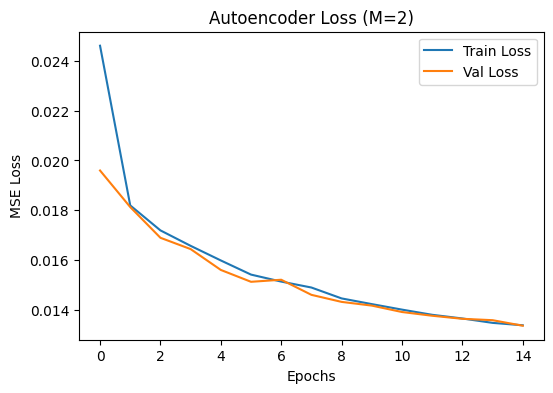


--- Έναρξη Εκπαίδευσης CNN Autoencoder για M = 10 ---
Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - loss: 0.0232 - val_loss: 0.0174
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 0.0137 - val_loss: 0.0109
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - loss: 0.0095 - val_loss: 0.0088
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - loss: 0.0078 - val_loss: 0.0075
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - loss: 0.0068 - val_loss: 0.0064
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step - loss: 0.0061 - val_loss: 0.0058
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - loss: 0.0055 - val_loss: 0.0053
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - loss: 0.0051 - val_loss: 0.0051
Epoch 9/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - loss: 0.0048 - val_loss: 0.0047
Epoch 10/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 0.0045 - val_loss: 0.0046
Epoch 11/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - loss: 0

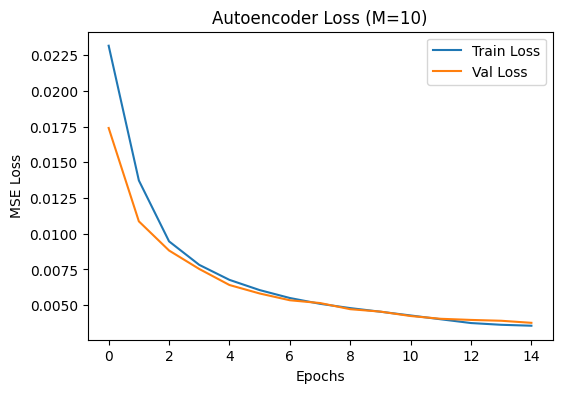


--- Έναρξη Εκπαίδευσης CNN Autoencoder για M = 50 ---
Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - loss: 0.0233 - val_loss: 0.0180
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 0.0123 - val_loss: 0.0100
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - loss: 0.0089 - val_loss: 0.0081
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 0.0072 - val_loss: 0.0067
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - loss: 0.0062 - val_loss: 0.0059
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 0.0054 - val_loss: 0.0052
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 0.0048 - val_loss: 0.0047
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 9/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - loss: 0.0041 - val_loss: 0.0040
Epoch 10/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - loss: 0.0038 - val_loss: 0.0037
Epoch 11/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 0

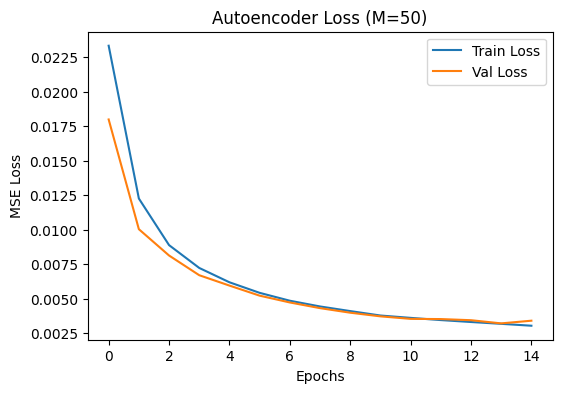


Το Βήμα 1 ολοκληρώθηκε με επιτυχία! Έχουμε έτοιμα τα συμπιεσμένα δεδομένα.


In [8]:
latent_dimensions = [2, 10, 50]
trained_encoders = {}
latent_features = {}

for M in latent_dimensions:
    print(f"\n--- Έναρξη Εκπαίδευσης CNN Autoencoder για M = {M} ---")
    
    autoencoder, encoder, decoder = build_cnn_autoencoder(latent_dim=M)
    
    autoencoder.compile(optimizer='adam', loss='mse')
    
    history = autoencoder.fit(
        X_train, X_train,
        epochs=15,            
        batch_size=64,
        validation_data=(X_val, X_val),
        verbose=1
    )
    
    trained_encoders[M] = encoder
    print(f"Εξαγωγή χαρακτηριστικών λανθάνοντος χώρου (M={M})...")
    latent_features[M] = {
        'train': encoder.predict(X_train),
        'val': encoder.predict(X_val),
        'test': encoder.predict(X_test_spatial)
    }
    
    plt.figure(figsize=(6, 4))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Autoencoder Loss (M={M})')
    plt.xlabel('Epochs')
    plt.ylabel('MSE Loss')
    plt.legend()
    plt.show()

print("\nΤο Βήμα 1 ολοκληρώθηκε με επιτυχία! Έχουμε έτοιμα τα συμπιεσμένα δεδομένα.")

## Ταξινόμηση με SVM στον λανθάνοντα χώρο

In [9]:
classification_results = []

C_best = 10
gamma_best = 0.1

def build_scaled_svm(C=C_best, gamma=gamma_best):
    return make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
    )

print("Έναρξη Ταξινόμησης με SVM (RBF Kernel) στα συμπιεσμένα χαρακτηριστικά...")

for M in latent_dimensions:
    print(f"\n--- Εκπαίδευση SVM για M = {M} ---")
    
    X_train_latent = latent_features[M]['train']
    X_val_latent = latent_features[M]['val']
    X_test_latent = latent_features[M]['test']
    

    svm_model = build_scaled_svm()
    
    start_time = time.time()
    svm_model.fit(X_train_latent, y_train)
    train_time = time.time() - start_time
    print(f"Ολοκλήρωση εκπαίδευσης σε {train_time:.2f} δευτερόλεπτα.")
    
    
    val_preds = svm_model.predict(X_val_latent)
    test_preds = svm_model.predict(X_test_latent)
    
    
    acc = accuracy_score(y_test, test_preds)
    prec = precision_score(y_test, test_preds, average='macro', zero_division=0)
    rec = recall_score(y_test, test_preds, average='macro', zero_division=0)
    f1 = f1_score(y_test, test_preds, average='macro', zero_division=0)
    
    val_acc = accuracy_score(y_val, val_preds)
    
    classification_results.append({
        'Latent Space (M)': M,
        'Val Accuracy (%)': round(val_acc * 100, 2),
        'Test Accuracy (%)': round(acc * 100, 2),
        'Test Precision': round(prec, 4),
        'Test Recall': round(rec, 4),
        'Test F1-Score': round(f1, 4),
        'SVM Train Time (s)': round(train_time, 1)
    })

df_classification = pd.DataFrame(classification_results)
print("\n--- ΣΥΓΚΕΝΤΡΩΤΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΤΑΞΙΝΟΜΗΣΗΣ (ΖΗΤΟΥΜΕΝΟ Α1) ---")
print(df_classification.to_string(index=False))


Έναρξη Ταξινόμησης με SVM (RBF Kernel) στα συμπιεσμένα χαρακτηριστικά...

--- Εκπαίδευση SVM για M = 2 ---
Ολοκλήρωση εκπαίδευσης σε 15.80 δευτερόλεπτα.

--- Εκπαίδευση SVM για M = 10 ---
Ολοκλήρωση εκπαίδευσης σε 3.67 δευτερόλεπτα.

--- Εκπαίδευση SVM για M = 50 ---
Ολοκλήρωση εκπαίδευσης σε 13.05 δευτερόλεπτα.

--- ΣΥΓΚΕΝΤΡΩΤΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΤΑΞΙΝΟΜΗΣΗΣ (ΖΗΤΟΥΜΕΝΟ Α1) ---
 Latent Space (M)  Val Accuracy (%)  Test Accuracy (%)  Test Precision  Test Recall  Test F1-Score  SVM Train Time (s)
                2             24.37              21.92          0.2737       0.2294         0.1721                15.8
               10             96.50              73.62          0.7372       0.7217         0.7214                 3.7
               50             99.64              81.62          0.8125       0.8129         0.8053                13.0


Έναρξη δοκιμών K-means για K από 2 έως 30...
Υπολογισμός Silhouette για M = 2...
Για M=2, το βέλτιστο K* είναι 2 με Silhouette Score: 0.4138
Υπολογισμός Silhouette για M = 10...
Για M=10, το βέλτιστο K* είναι 2 με Silhouette Score: 0.1902
Υπολογισμός Silhouette για M = 50...
Για M=50, το βέλτιστο K* είναι 2 με Silhouette Score: 0.1846
--- ΒΕΛΤΙΣΤΟ K* ΜΕ K-MEANS / SILHOUETTE ---
 Latent Space (M)  Best K*  Best Silhouette
                2        2           0.4138
               10        2           0.1902
               50        2           0.1846


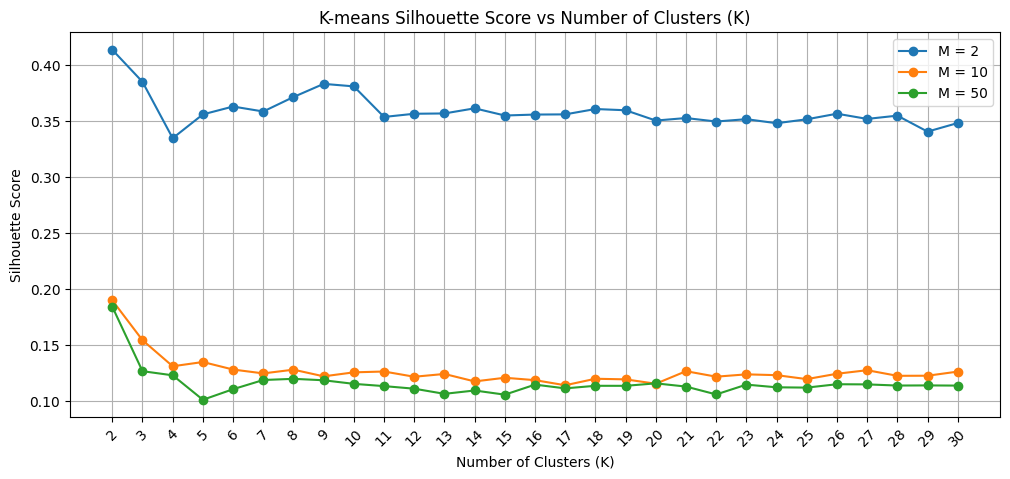

In [ ]:
k_values = list(range(2, 31))
kmeans_silhouette_results = {}
best_k_by_M = {}
best_kmeans_score_by_M = {}
kmeans_summary = []

print("Έναρξη δοκιμών K-means για K από 2 έως 30...")

for M in latent_dimensions:
    print(f"Υπολογισμός Silhouette για M = {M}...")
    X_clustering = StandardScaler().fit_transform(latent_features[M]['val'])
    scores = []
    
    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
        cluster_labels = kmeans.fit_predict(X_clustering)
        score = silhouette_score(X_clustering, cluster_labels)
        scores.append(score)
        
    kmeans_silhouette_results[M] = scores
    best_idx = int(np.argmax(scores))
    best_k = k_values[best_idx]
    best_score = scores[best_idx]
    best_k_by_M[M] = best_k
    best_kmeans_score_by_M[M] = best_score
    
    kmeans_summary.append({
        'Latent Space (M)': M,
        'Best K*': best_k,
        'Best Silhouette': round(best_score, 4)
    })
    
    print(f"Για M={M}, το βέλτιστο K* είναι {best_k} με Silhouette Score: {best_score:.4f}")

print("--- ΒΕΛΤΙΣΤΟ K* ΜΕ K-MEANS / SILHOUETTE ---")
print(pd.DataFrame(kmeans_summary).to_string(index=False))

plt.figure(figsize=(12, 5))
for M in latent_dimensions:
    plt.plot(k_values, kmeans_silhouette_results[M], marker='o', label=f'M = {M}')
plt.title('K-means Silhouette Score vs Number of Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values, rotation=45)
plt.legend()
plt.grid(True)
plt.show()


## ΟΠΤΙΚΟΠΟΙΗΣΗ ΔΕΔΟΜΕΝΩΝ ΚΑΙ ΔΕΝΔΡΟΓΡΑΜΜΑΤΩΝ 

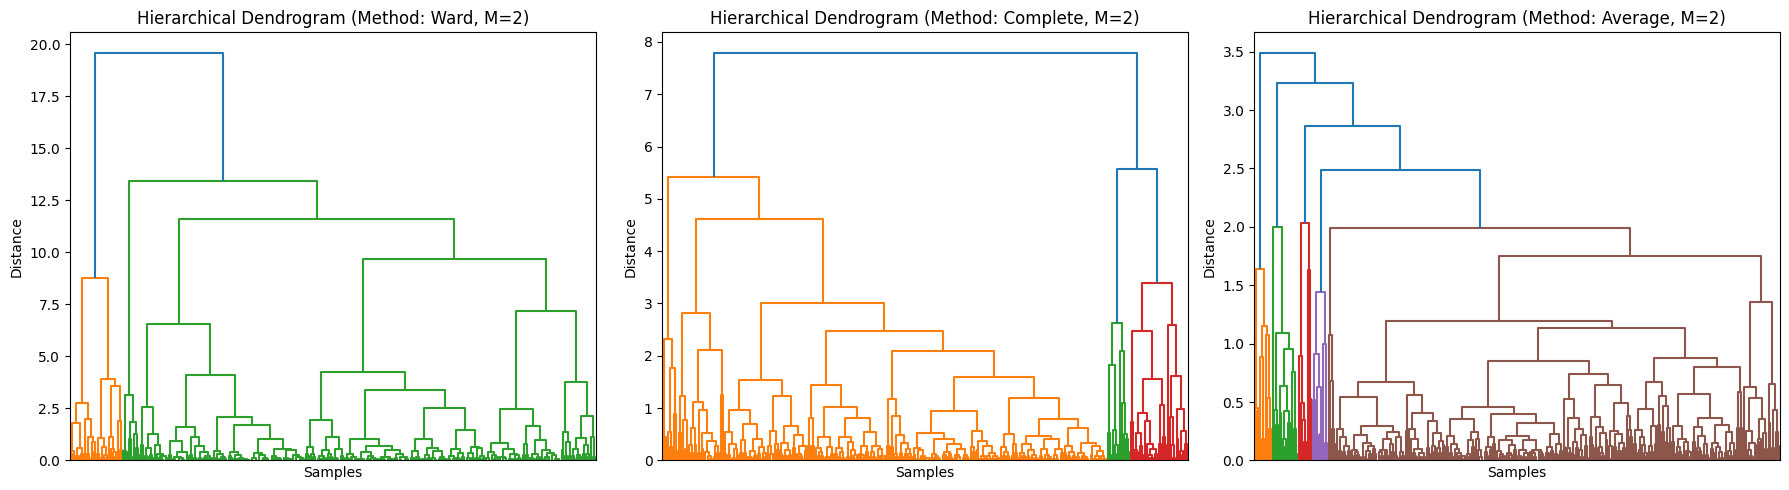

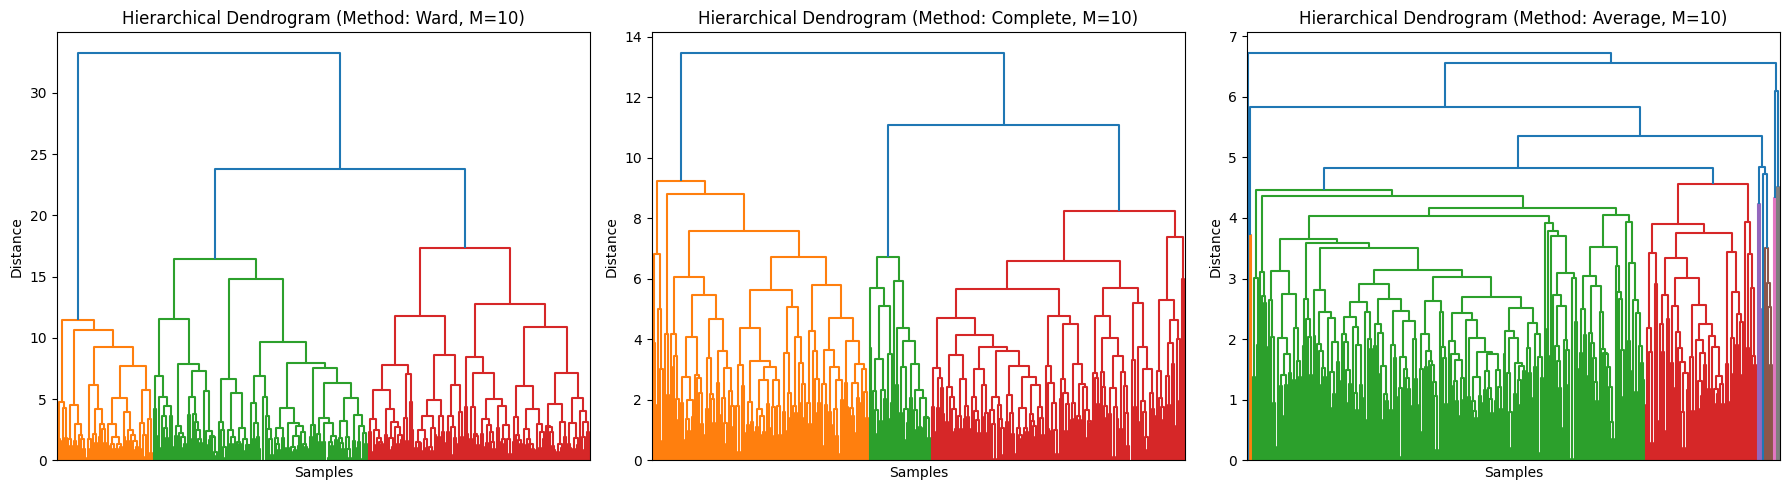

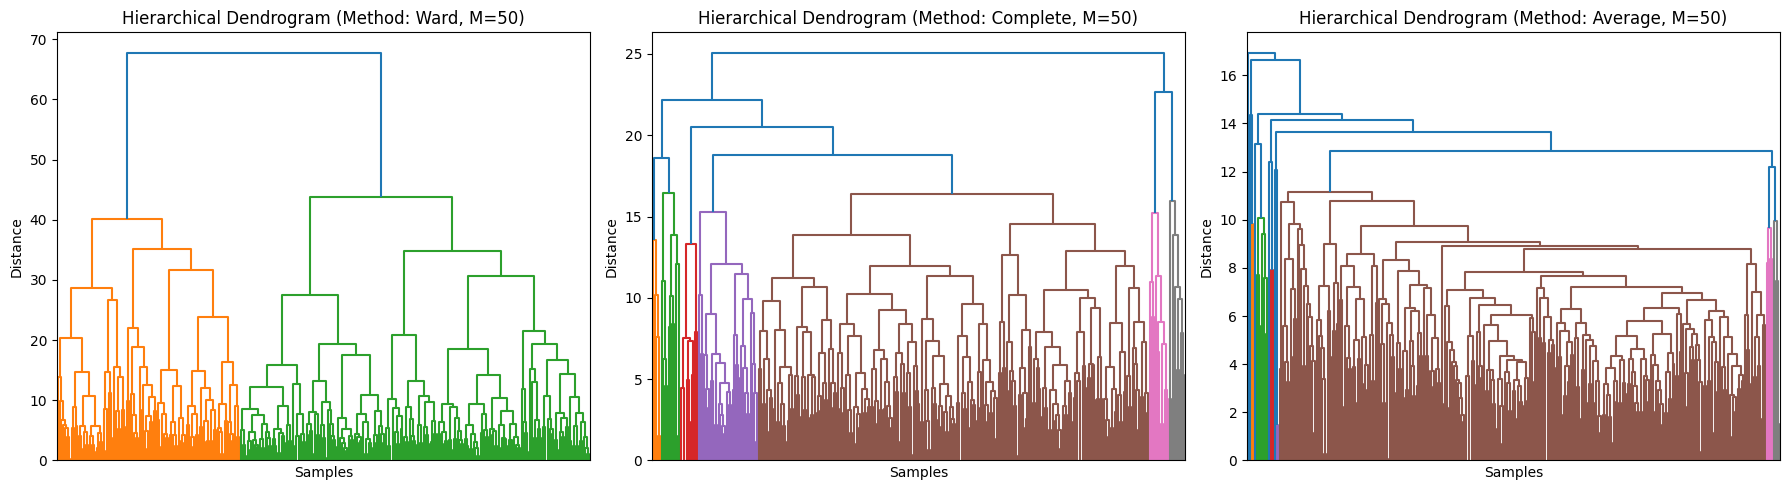

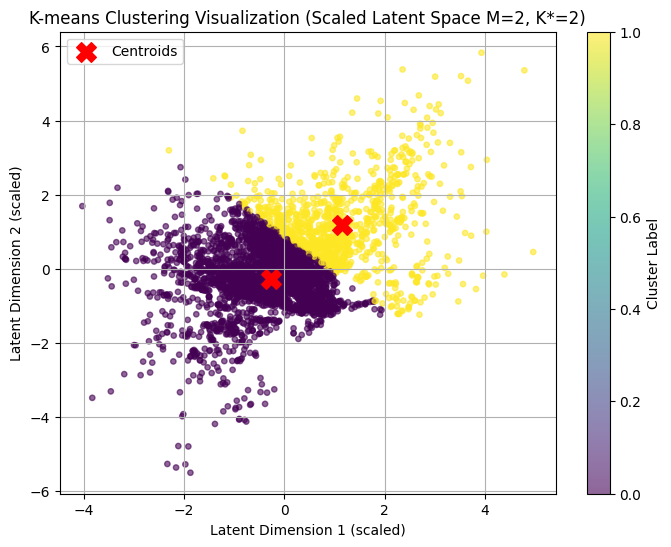

In [ ]:
scaled_val_features = {
    M: StandardScaler().fit_transform(latent_features[M]['val'])
    for M in latent_dimensions
}

linkage_methods = ['ward', 'complete', 'average']
rng = np.random.default_rng(42)

for M in latent_dimensions:
    X_for_dendrogram = scaled_val_features[M]
    sample_size = min(300, len(X_for_dendrogram))
    sample_indices = rng.choice(len(X_for_dendrogram), size=sample_size, replace=False)
    X_sample = X_for_dendrogram[sample_indices]
    
    plt.figure(figsize=(18, 5))
    for i, method in enumerate(linkage_methods, 1):
        plt.subplot(1, 3, i)
        linkage_matrix = sch.linkage(X_sample, method=method, metric='euclidean')
        sch.dendrogram(linkage_matrix, no_labels=True)
        plt.title(f'Hierarchical Dendrogram (Method: {method.capitalize()}, M={M})')
        plt.xlabel('Samples')
        plt.ylabel('Distance')
    
    plt.tight_layout()
    plt.show()

X_val_2D = scaled_val_features[2]
k_star_2D = best_k_by_M[2]
kmeans_2D = KMeans(n_clusters=k_star_2D, n_init=20, random_state=42)
cluster_labels_2D = kmeans_2D.fit_predict(X_val_2D)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_val_2D[:, 0],
    X_val_2D[:, 1],
    c=cluster_labels_2D,
    cmap='viridis',
    alpha=0.6,
    s=15
)
centroids = kmeans_2D.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')

plt.title(f'K-means Clustering Visualization (Scaled Latent Space M=2, K*={k_star_2D})')
plt.xlabel('Latent Dimension 1 (scaled)')
plt.ylabel('Latent Dimension 2 (scaled)')
plt.colorbar(scatter, label='Cluster Label')
plt.legend()
plt.grid(True)
plt.show()


## ΣΥΓΚΡΙΣΗ K-MEANS vs AGGLOMERATIVE CLUSTERING


In [ ]:
def make_agglomerative(n_clusters, linkage):
    try:
        return AgglomerativeClustering(
            n_clusters=n_clusters,
            metric='euclidean',
            linkage=linkage
        )
    except TypeError:
        return AgglomerativeClustering(
            n_clusters=n_clusters,
            affinity='euclidean',
            linkage=linkage
        )

max_agg_samples = 3000
comparison_rows = []
rng = np.random.default_rng(42)

for M in latent_dimensions:
    X_full = StandardScaler().fit_transform(latent_features[M]['val'])
    k_star = best_k_by_M[M]
    sample_size = min(max_agg_samples, len(X_full))
    sample_indices = rng.choice(len(X_full), size=sample_size, replace=False)
    X_comp = X_full[sample_indices]
    
    km = KMeans(n_clusters=k_star, n_init=20, random_state=42)
    km_labels = km.fit_predict(X_comp)
    km_score = silhouette_score(X_comp, km_labels)
    comparison_rows.append({
        'M': M,
        'K*': k_star,
        'Algorithm': 'K-means',
        'Linkage': '-',
        'Silhouette': round(km_score, 4),
        'Samples': sample_size
    })
    
    for method in ['ward', 'complete', 'average']:
        agg = make_agglomerative(n_clusters=k_star, linkage=method)
        agg_labels = agg.fit_predict(X_comp)
        agg_score = silhouette_score(X_comp, agg_labels)
        comparison_rows.append({
            'M': M,
            'K*': k_star,
            'Algorithm': 'Agglomerative',
            'Linkage': method,
            'Silhouette': round(agg_score, 4),
            'Samples': sample_size
        })

df_clustering_comparison = pd.DataFrame(comparison_rows)
print("--- ΣΥΓΚΡΙΣΗ K-MEANS vs AGGLOMERATIVE ΜΕ ΤΟ ΙΔΙΟ K* ---")
print(df_clustering_comparison.to_string(index=False))

--- ΣΥΓΚΡΙΣΗ K-MEANS vs AGGLOMERATIVE ΜΕ ΤΟ ΙΔΙΟ K* ---
 M  K*     Algorithm  Linkage  Silhouette  Samples
 2   2       K-means        -      0.4095     3000
 2   2 Agglomerative     ward      0.3293     3000
 2   2 Agglomerative complete      0.5780     3000
 2   2 Agglomerative  average      0.6154     3000
10   2       K-means        -      0.1890     3000
10   2 Agglomerative     ward      0.1931     3000
10   2 Agglomerative complete      0.1835     3000
10   2 Agglomerative  average      0.4036     3000
50   2       K-means        -      0.1883     3000
50   2 Agglomerative     ward      0.1266     3000
50   2 Agglomerative complete      0.2505     3000
50   2 Agglomerative  average      0.4361     3000


## UNCONDITIONAL VAE (M=2)

In [5]:
# Reparameterization Trick: αντί άμεσης δειγματοληψίας από N(μ, σ²) (non-differentiable),
# υπολογίζει z = μ + σ*ε όπου ε ~ N(0,1), επιτρέποντας το backpropagation μέσω z
class Sampling(layers.Layer):

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        # Τυχαίος θόρυβος ε ~ N(0,1) - ο μόνος μη-αιτιοκρατικός παράγοντας
        epsilon = tf.random.normal(shape=(batch, dim))
        # z = μ + exp(0.5 * log_var) * ε  <=>  z = μ + σ * ε
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


# KL divergence layer: το KL loss υπολογίζεται μέσα σε Keras layer,
# ώστε να μη χρησιμοποιούνται απευθείας TensorFlow ops πάνω σε KerasTensors.
class KLDivergenceLayer(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var, z = inputs

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1
            )
        )

        self.add_loss(kl_loss)
        return z


# Λανθάνων χώρος 2D για ευκολία οπτικοποίησης του latent space
latent_dim = 2


# --- ENCODER VAE: Εξαγωγή παραμέτρων κατανομής q(z|x) ---
encoder_inputs = layers.Input(shape=(28, 28, 1), name="VAE_Encoder_Input")
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(encoder_inputs)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)

# Δύο παράλληλα στρώματα: μέση τιμή και λογάριθμος διασποράς της κατανομής q(z|x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
# Δειγματοληψία z από N(z_mean, exp(z_log_var)) μέσω reparameterization trick
z = Sampling()([z_mean, z_log_var])

# Ο encoder επιστρέφει z_mean, z_log_var, z - και τα τρία χρειάζονται για το KL loss
encoder_vae = models.Model(encoder_inputs, [z_mean, z_log_var, z], name="VAE_Encoder")


# --- DECODER VAE: Ανακατασκευή εικόνας p(x|z) από σημείο z ---
decoder_inputs = layers.Input(shape=(latent_dim,), name="VAE_Decoder_Input")
x = layers.Dense(32, activation='relu')(decoder_inputs)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(7 * 7 * 64, activation='relu')(x)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same')(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(x)
# Sigmoid: pixel values στο [0,1] - συμβατό με τα κανονικοποιημένα δεδομένα
decoder_outputs = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same', name="VAE_Decoder_Output")(x)

decoder_vae = models.Model(decoder_inputs, decoder_outputs, name="VAE_Decoder")


# --- ΠΛΗΡΕΣ VAE: ίδια λογική με autoencoder, αλλά με KL loss στο graph ---
vae_input = layers.Input(shape=(28, 28, 1), name="VAE_Input")
z_mean, z_log_var, z = encoder_vae(vae_input)
z = KLDivergenceLayer(name="kl_loss_layer")([z_mean, z_log_var, z])
reconstruction = decoder_vae(z)


def recon_loss(y_true, y_pred):
    return tf.reduce_mean(
        tf.reduce_sum(tf.square(y_true - y_pred), axis=(1, 2, 3))
    )


vae_model = models.Model(vae_input, reconstruction, name="VAE")
vae_model.compile(optimizer='adam', loss=recon_loss)

# EarlyStopping: τερματισμός αν το val_loss δεν βελτιώνεται για 3 epochs
EPOCHS_VAE = 20
early_stop_vae = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("--- Έναρξη Εκπαίδευσης Unconditional VAE (M = 2) ---")
vae_history = vae_model.fit(
    X_train,
    X_train,
    epochs=EPOCHS_VAE,
    batch_size=64,
    validation_data=(X_val, X_val),
    callbacks=[early_stop_vae]
)

print("Εξαγωγή χαρακτηριστικών λανθάνοντος χώρου VAE...")
vae_latent_features = {
    # [0] = z_mean: αιτιοκρατική αναπαράσταση για inference (αντί του stochastic z)
    'train': encoder_vae.predict(X_train, verbose=0)[0],
    'val': encoder_vae.predict(X_val, verbose=0)[0],
    'test': encoder_vae.predict(X_test_spatial, verbose=0)[0]
}
print("Η εξαγωγή ολοκληρώθηκε.")



--- Έναρξη Εκπαίδευσης Unconditional VAE (M = 2) ---
Epoch 1/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - loss: 23.1429 - val_loss: 20.2816
Epoch 2/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 20.1304 - val_loss: 20.0606
Epoch 3/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 20.0016 - val_loss: 20.8994
Epoch 4/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 20.0362 - val_loss: 19.8796
Epoch 5/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 19.9017 - val_loss: 19.4128
Epoch 6/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - loss: 18.5665 - val_loss: 18.3815
Epoch 7/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - loss: 18.0408 - val_loss: 17.8222
Epoch 8/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - loss: 17.8227 - val_loss: 17.7862
Epoch 9/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - loss: 17.7797 - val_loss: 17.7272
Epoch 10/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - loss: 17.6486 - val_loss: 17.5773
Epoch 11/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 

## CONDITIONAL VAE (CVAE)

In [6]:
# One-hot encoding ετικετών: αριθμός -> binary vector
# Αυτό είναι το condition c που ελέγχει το CVAE
c_train = to_categorical(remap_labels(y_train), num_classes=num_classes)
c_val = to_categorical(remap_labels(y_val), num_classes=num_classes)
c_test = to_categorical(remap_labels(y_test), num_classes=num_classes)


# --- ENCODER CVAE: Εξαγωγή παραμέτρων q(z|x,c) ---
cvae_encoder_img_input = layers.Input(shape=(28, 28, 1), name="CVAE_Image_Input")
cvae_encoder_label_input = layers.Input(shape=(num_classes,), name="CVAE_Label_Input")

x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(cvae_encoder_img_input)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Flatten()(x)

# Conditioning: συνένωση χαρακτηριστικών εικόνας με την ετικέτα c
x = layers.Concatenate()([x, cvae_encoder_label_input])

x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)

# Παράμετροι κατανομής q(z|x,c)
z_mean_c = layers.Dense(latent_dim, name="z_mean_c")(x)
z_log_var_c = layers.Dense(latent_dim, name="z_log_var_c")(x)

# Δειγματοληψία z από N(z_mean_c, exp(z_log_var_c)) μέσω reparameterization trick
z_c = Sampling()([z_mean_c, z_log_var_c])

# Ο encoder επιστρέφει z_mean, z_log_var, z όπως και στο VAE
encoder_cvae = models.Model(
    [cvae_encoder_img_input, cvae_encoder_label_input],
    [z_mean_c, z_log_var_c, z_c],
    name="CVAE_Encoder"
)


# --- DECODER CVAE: Ανακατασκευή εικόνας p(x|z,c) ---
cvae_decoder_z_input = layers.Input(shape=(latent_dim,), name="CVAE_Decoder_Z_Input")
cvae_decoder_label_input = layers.Input(shape=(num_classes,), name="CVAE_Decoder_Label_Input")

# Conditioning: ο decoder λαμβάνει και το z και την ετικέτα c
x = layers.Concatenate()([cvae_decoder_z_input, cvae_decoder_label_input])

x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(7 * 7 * 64, activation='relu')(x)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same')(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(x)

cvae_decoder_outputs = layers.Conv2D(
    1,
    (3, 3),
    activation='sigmoid',
    padding='same',
    name="CVAE_Decoder_Output"
)(x)

decoder_cvae = models.Model(
    [cvae_decoder_z_input, cvae_decoder_label_input],
    cvae_decoder_outputs,
    name="CVAE_Decoder"
)


# --- ΠΛΗΡΕΣ CVAE: ίδια μορφή με το VAE, αλλά με condition c ---
cvae_img_input = layers.Input(shape=(28, 28, 1), name="CVAE_Input_Image")
cvae_label_input = layers.Input(shape=(num_classes,), name="CVAE_Input_Label")

z_mean_c, z_log_var_c, z_c = encoder_cvae([cvae_img_input, cvae_label_input])

# Προσθήκη KL loss μέσα στο graph του Keras
z_c = KLDivergenceLayer(name="cvae_kl_loss_layer")([z_mean_c, z_log_var_c, z_c])

# Ανακατασκευή εικόνας με βάση z και condition c
cvae_reconstruction = decoder_cvae([z_c, cvae_label_input])


def cvae_recon_loss(y_true, y_pred):
    return tf.reduce_mean(
        tf.reduce_sum(tf.square(y_true - y_pred), axis=(1, 2, 3))
    )


cvae_model = models.Model(
    [cvae_img_input, cvae_label_input],
    cvae_reconstruction,
    name="CVAE"
)

cvae_model.compile(
    optimizer='adam',
    loss=cvae_recon_loss
)


early_stop_cvae = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


print("--- Έναρξη Εκπαίδευσης Conditional VAE (CVAE, M=2) ---")
cvae_history = cvae_model.fit(
    [X_train, c_train],
    X_train,
    epochs=EPOCHS_VAE,
    batch_size=64,
    validation_data=([X_val, c_val], X_val),
    callbacks=[early_stop_cvae]
)


# Oracle condition: χρήση πραγματικής ετικέτας κατά την κωδικοποίηση
# Δίνει διαγνωστική εικόνα για τη συμπεριφορά του CVAE όταν το πραγματικό label είναι γνωστό
print("Εξαγωγή χαρακτηριστικών λανθάνοντος χώρου CVAE με oracle condition c=y...")
cvae_latent_features_oracle = {
    'train': encoder_cvae.predict([X_train, c_train], verbose=0)[0],
    'val': encoder_cvae.predict([X_val, c_val], verbose=0)[0],
    'test': encoder_cvae.predict([X_test_spatial, c_test], verbose=0)[0]
}


# Zero condition: μηδενικό condition vector, χωρίς πληροφορία κλάσης
# Εξομοιώνει inference χωρίς γνώση των labels για πιο δίκαιη σύγκριση
c_train_zero = np.zeros_like(c_train)
c_val_zero = np.zeros_like(c_val)
c_test_zero = np.zeros_like(c_test)

print("Εξαγωγή χαρακτηριστικών CVAE χωρίς oracle labels (zero condition)...")
cvae_latent_features_zero = {
    'train': encoder_cvae.predict([X_train, c_train_zero], verbose=0)[0],
    'val': encoder_cvae.predict([X_val, c_val_zero], verbose=0)[0],
    'test': encoder_cvae.predict([X_test_spatial, c_test_zero], verbose=0)[0]
}

print("Η εξαγωγή ολοκληρώθηκε.")


--- Έναρξη Εκπαίδευσης Conditional VAE (CVAE, M=2) ---
Epoch 1/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - loss: 21.6795 - val_loss: 17.3149
Epoch 2/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - loss: 16.6418 - val_loss: 15.6178
Epoch 3/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 15.0770 - val_loss: 14.9399
Epoch 4/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 14.5665 - val_loss: 14.3381
Epoch 5/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - loss: 14.1350 - val_loss: 14.2958
Epoch 6/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - loss: 13.8569 - val_loss: 14.4090
Epoch 7/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - loss: 13.6789 - val_loss: 13.8366
Epoch 8/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - loss: 13.4589 - val_loss: 13.5290
Epoch 9/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 13.3017 - val_loss: 13.3719
Epoch 10/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 13.1777 - val_loss: 13.1890
Epoch 11/20
344/344 ━━━━━━━━━━━━━━━━━━━━ 13s

## PCA

Εφαρμογή PCA (2 components) στα αρχικά δεδομένα...


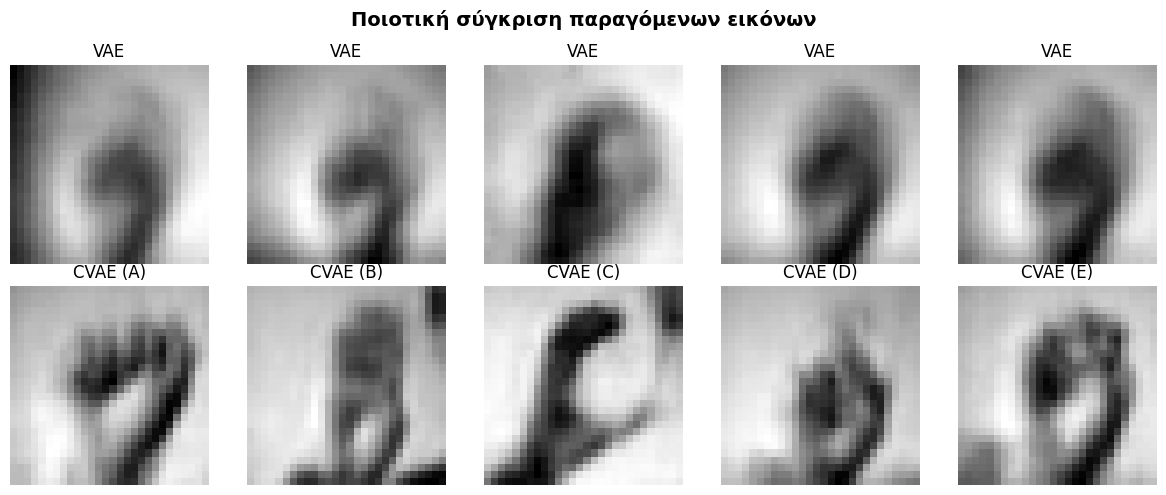

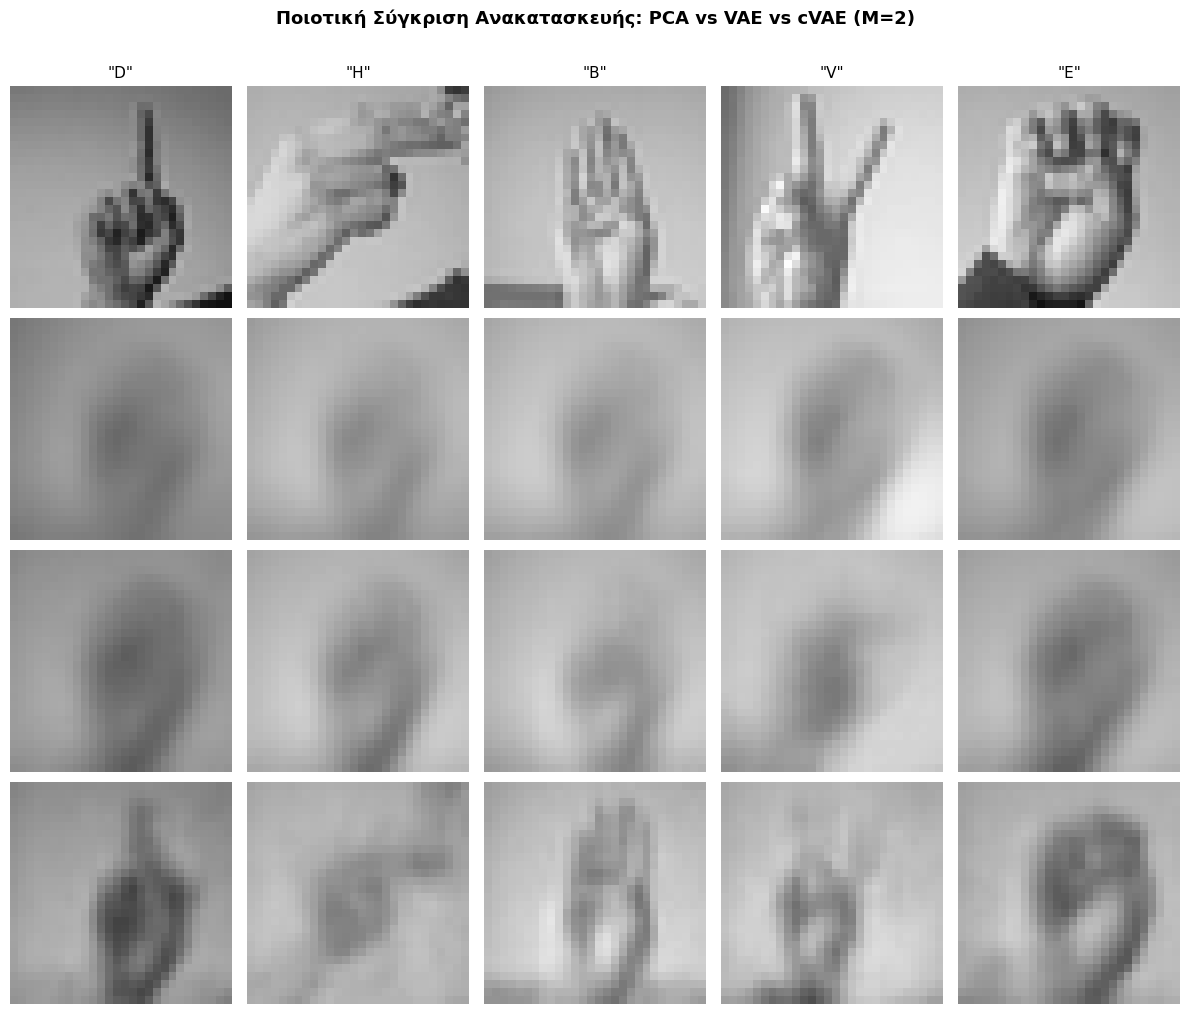

Εκτέλεση SVM ταξινόμησης στους λανθάνοντες χώρους (PCA, VAE, CVAE)...
--- ΤΕΛΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΠΟΣΟΤΙΚΗΣ ΣΥΓΚΡΙΣΗΣ (ΖΗΤΟΥΜΕΝΟ Β2) ---
             Latent Space (2D)  Test Accuracy (%)  Test Precision  Test Recall  Test F1-Score  Train Time (s)
                           PCA              10.67          0.1394       0.1119         0.0716            19.5
                           VAE              16.90          0.1865       0.1824         0.1241            15.8
          CVAE (zero c - fair)               8.16          0.0630       0.0824         0.0575            22.6
CVAE (oracle c=y - diagnostic)               6.11          0.0614       0.0729         0.0449            25.6
Σημείωση: για δίκαιη ταξινόμηση χρησιμοποιούμε τη γραμμή CVAE (zero c - fair).


In [7]:
print("Εφαρμογή PCA (2 components) στα αρχικά δεδομένα...")
# Ισοπέδωση 28x28 εικόνων σε 784-dimensional διανύσματα για είσοδο στο PCA
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test_spatial.reshape(X_test_spatial.shape[0], -1)

# PCA fit μόνο στο training set για αποφυγή data leakage
pca = PCA(n_components=2, random_state=42)
pca_features = {
    'train': pca.fit_transform(X_train_flat),
    'val': pca.transform(X_val_flat),
    'test': pca.transform(X_test_flat)
}

# Σε περίπτωση που το cell του SVM helper δεν έχει εκτελεστεί στην τρέχουσα συνεδρία.
try:
    build_scaled_svm
except NameError:
    def build_scaled_svm(C=10, gamma=0.1):
        return make_pipeline(
            StandardScaler(),
            SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)
        )


# Τυχαία σημεία z ~ N(0,1) στον 2D λανθάνοντα χώρο για δημιουργία νέων εικόνων
rng = np.random.default_rng(42)
random_noise = rng.normal(size=(5, latent_dim)).astype('float32')

# VAE: τυχαία γέννηση χωρίς conditioning - άγνωστη κλάση εξόδου
generated_vae = decoder_vae.predict(random_noise, verbose=0)

# CVAE: στοχευμένη γέννηση γραμμάτων A, B, C, D, E μέσω conditioning
labels_to_generate = np.array([0, 1, 2, 3, 4])
c_generate = to_categorical(remap_labels(labels_to_generate), num_classes=num_classes)
generated_cvae = decoder_cvae.predict([random_noise, c_generate], verbose=0)

# Οπτική σύγκριση: VAE (τυχαία) vs CVAE (κατ'απαίτηση) στα ίδια z points
plt.figure(figsize=(12, 5))
for i, label in enumerate(labels_to_generate):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(generated_vae[i].reshape(28, 28), cmap='gray')
    ax.set_title("VAE")
    ax.axis('off')

    ax = plt.subplot(2, 5, i + 6)
    plt.imshow(generated_cvae[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"CVAE ({label_to_asl_letter(label)})")
    ax.axis('off')

plt.suptitle("Ποιοτική σύγκριση παραγόμενων εικόνων", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Επιλογή 5 τυχαίων εικόνων από το test set για ποιοτική σύγκριση ανακατασκευής
rng_vis = np.random.default_rng(0)
sample_idx = rng_vis.choice(len(X_test_spatial), size=5, replace=False)

X_samples = X_test_spatial[sample_idx]
c_samples = c_test[sample_idx]

# PCA ανακατασκευή: project σε 2D, inverse_transform στο 784D pixel space
X_samples_flat = X_samples.reshape(5, -1)
X_pca_proj = pca.transform(X_samples_flat)
X_pca_recon = pca.inverse_transform(X_pca_proj).reshape(5, 28, 28)

# VAE ανακατασκευή: χρήση z_mean (αιτιοκρατική) αντί stochastic z
z_mean_vae, _, _ = encoder_vae.predict(X_samples, verbose=0)
X_vae_recon = decoder_vae.predict(z_mean_vae, verbose=0).reshape(5, 28, 28)

# CVAE ανακατασκευή με oracle condition: γνωστές ετικέτες για ποιοτική σύγκριση
z_mean_cvae, _, _ = encoder_cvae.predict([X_samples, c_samples], verbose=0)
X_cvae_recon = decoder_cvae.predict([z_mean_cvae, c_samples], verbose=0).reshape(5, 28, 28)

# Πλέγμα 4x5: κάθε γραμμή μια μέθοδος ανακατασκευής, κάθε στήλη ένα δείγμα
rows = ['Original', 'PCA (M=2)', 'VAE (M=2)', 'cVAE (M=2)']
images_per_row = [
    X_samples.reshape(5, 28, 28),
    X_pca_recon,
    X_vae_recon,
    X_cvae_recon
]

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for row_idx, (row_label, imgs) in enumerate(zip(rows, images_per_row)):
    for col_idx in range(5):
        ax = axes[row_idx, col_idx]
        ax.imshow(imgs[col_idx], cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if col_idx == 0:
            ax.set_ylabel(row_label, fontsize=11, fontweight='bold', labelpad=10)
        if row_idx == 0:
            letter = label_to_asl_letter(y_test[sample_idx[col_idx]])
            ax.set_title(f'"{letter}"', fontsize=11)

plt.suptitle('Ποιοτική Σύγκριση Ανακατασκευής: PCA vs VAE vs cVAE (M=2)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


# Τελική ποσοτική σύγκριση: SVM σε 4 διαφορετικούς 2D λανθάνοντες χώρους
print("Εκτέλεση SVM ταξινόμησης στους λανθάνοντες χώρους (PCA, VAE, CVAE)...")
final_results = []

# PCA: γραμμική μέθοδος | VAE: μη-γραμμική | CVAE zero: δίκαιη | CVAE oracle: διαγνωστική
spaces = {
    'PCA': pca_features,
    'VAE': vae_latent_features,
    'CVAE (zero c - fair)': cvae_latent_features_zero,
    'CVAE (oracle c=y - diagnostic)': cvae_latent_features_oracle
}

for name, space in spaces.items():
    svm = build_scaled_svm(C=10, gamma=0.1)
    start = time.time()
    svm.fit(space['train'], y_train)
    t_time = time.time() - start

    preds = svm.predict(space['test'])
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='macro', zero_division=0)
    rec = recall_score(y_test, preds, average='macro', zero_division=0)
    f1 = f1_score(y_test, preds, average='macro', zero_division=0)

    final_results.append({
        'Latent Space (2D)': name,
        'Test Accuracy (%)': round(acc * 100, 2),
        'Test Precision': round(prec, 4),
        'Test Recall': round(rec, 4),
        'Test F1-Score': round(f1, 4),
        'Train Time (s)': round(t_time, 1)
    })

print("--- ΤΕΛΙΚΑ ΑΠΟΤΕΛΕΣΜΑΤΑ ΠΟΣΟΤΙΚΗΣ ΣΥΓΚΡΙΣΗΣ (ΖΗΤΟΥΜΕΝΟ Β2) ---")
print(pd.DataFrame(final_results).to_string(index=False))
print("Σημείωση: για δίκαιη ταξινόμηση χρησιμοποιούμε τη γραμμή CVAE (zero c - fair).")
